# Figure 1 — Short- vs. long-read RNA-seq on the DM genome and the haplotype-resolved Désirée genome

Panels (A is the schematic, not generated here):
- **B.** Per-locus unique mapping rate of single-isoform genes, long- vs. short-read, DM (top) and haplotype-resolved (bottom)
- **C.** Correlation of heat-vs-control log2FC between short- and long-read RNA-seq, DM (top) and haplotype-resolved (bottom)
- **D.** Overlap of DEGs (|log2FC| > 1, adj. p < 0.01) detected by long- and short-read RNA-seq, DM (top) and haplotype-resolved (bottom)
- **E.** log2FC correlation split by average transcript length (DM genome)
- **F.** log2FC correlation split by per-locus unique mapping rate (haplotype-resolved genome)

Source notebooks:
- `ANALYSIS/Reference_comparison/Unitato_vs_desiree_liftoff.ipynb` (B)
- `ANALYSIS/notebooks/0_notebooks_for_paper/0_DEGene_Kinnex_vs_Illumina_combat_limma.ipynb` (C/D top, E)
- `ANALYSIS/notebooks/0_notebooks_for_paper/0_DEAllele_Kinnex_vs_Illumina_combat_limma.ipynb` (C/D bottom, F)

Inputs: `clean_data/Fig1_short_vs_long_read_comparison/` (generated by `prepare_fig1_data.R` and `prepare_fig1_panelB.py` in the same folder)

In [27]:
suppressPackageStartupMessages({
  library(dplyr)
  library(readr)
  library(ggplot2)
  library(viridis)
  library(patchwork)
  library(VennDiagram)
  library(grid)
  library(svglite)
})

## Setup

In [28]:
DATA_DIR <- "../clean_data/Fig1_short_vs_long_read_comparison"
OUT_DIR  <- "./figures/Fig1"
dir.create(OUT_DIR, showWarnings = FALSE, recursive = TRUE)

FONTSIZE <- 20
LOGFC_CUT <- 1
ADJP_CUT  <- 0.01

## Load DE results

voom/limma heat-vs-control tables (with functional annotation and average CPM per condition) for:
- long-read (PacBio Kinnex, oarfish) counts, ComBat-seq batch-corrected and uncorrected
- short-read (Illumina, salmon/tximport) counts

Expression filter: CPM > 3 in ≥ 5 samples (DM) and CPM > 4 in ≥ 6 samples (haplotype-resolved).

In [29]:
read_de <- function(file) {
  res <- as.data.frame(read_csv(file.path(DATA_DIR, file), show_col_types = FALSE))
  rownames(res) <- res$gene_id
  res
}

dm_long   <- read_de("DE_DM_long_corrected.csv")
dm_uncorr <- read_de("DE_DM_long_uncorrected.csv")
dm_short  <- read_de("DE_DM_short.csv")

hap_long   <- read_de("DE_hap_long_corrected.csv")
hap_uncorr <- read_de("DE_hap_long_uncorrected.csv")
hap_short  <- read_de("DE_hap_short.csv")

## Shared plotting helper for the log2FC hexbin panels (C, E, F)

In [30]:
logfc_hex_plot <- function(data, facet = NULL, digits = 2) {
  ann <- data %>%
    group_by(across(all_of(facet))) %>%
    summarise(r = cor(logFC_short, logFC_long), n = n(), .groups = "drop") %>%
    mutate(label = paste0("Pearson r = ", sprintf(paste0("%.", digits, "f"), r), "\nn = ", n))
  print(ann)

  p <- ggplot(data, aes(x = logFC_short, y = logFC_long)) +
    geom_hex(bins = 30) +
    scale_fill_viridis(option = "turbo", trans = "log10", name = "count") +
    geom_label(data = ann,
               aes(x = -Inf, y = Inf, label = label),
               hjust = -0.05, vjust = 1.1,
               size = FONTSIZE - 13,
               fill = "white", alpha = 0.5, label.size = 0,
               inherit.aes = FALSE) +
    coord_fixed(ratio = 1, xlim = c(-5, 5), ylim = c(-5, 5)) +
    labs(
      x = expression("short-read RNA-seq " * log[2] * "FC(CPM)"),
      y = expression("long-read RNA-seq " * log[2] * "FC(CPM)")
    ) +
    theme_minimal(base_size = FONTSIZE) +
    theme(
      text = element_text(size = FONTSIZE),
      axis.text = element_text(size = FONTSIZE - 4),
      strip.text = element_text(size = FONTSIZE + 2, face = "bold"),
      legend.title = element_text(size = FONTSIZE - 2),
      legend.text = element_text(size = FONTSIZE - 4),
      panel.grid = element_blank(),
      axis.line = element_line(color = "black"),
      axis.ticks = element_line(color = "black")
    )
  if (!is.null(facet)) p <- p + facet_wrap(as.formula(paste("~", facet)), nrow = 1)
  p
}

# genes tested by both technologies, long-read logFC from the batch-corrected fit
paired_logfc <- function(long, short, genes) {
  data.frame(gene_id = genes, logFC_long = long[genes, "logFC"], logFC_short = short[genes, "logFC"])
}

## Panel B — Per-locus unique mapping rate (single-isoform genes)

Fraction of reads assigned uniquely to a gene (unique / (unique + ambiguous)), for genes with a
single annotated isoform and > 20 reads, kept if present in both technologies. Reads are summed
over all 8 samples (4 control, 4 heat; see `prepare_fig1_panelB.py`). Broken y-axis: the upper panel
starts at 5,000; the lower panel goes up to the tallest bar below 5,000.


 long RNA-seq haploid   long RNA-seq phased short RNA-seq haploid 
                17097                 50818                 17097 
 short RNA-seq phased 
                50818 


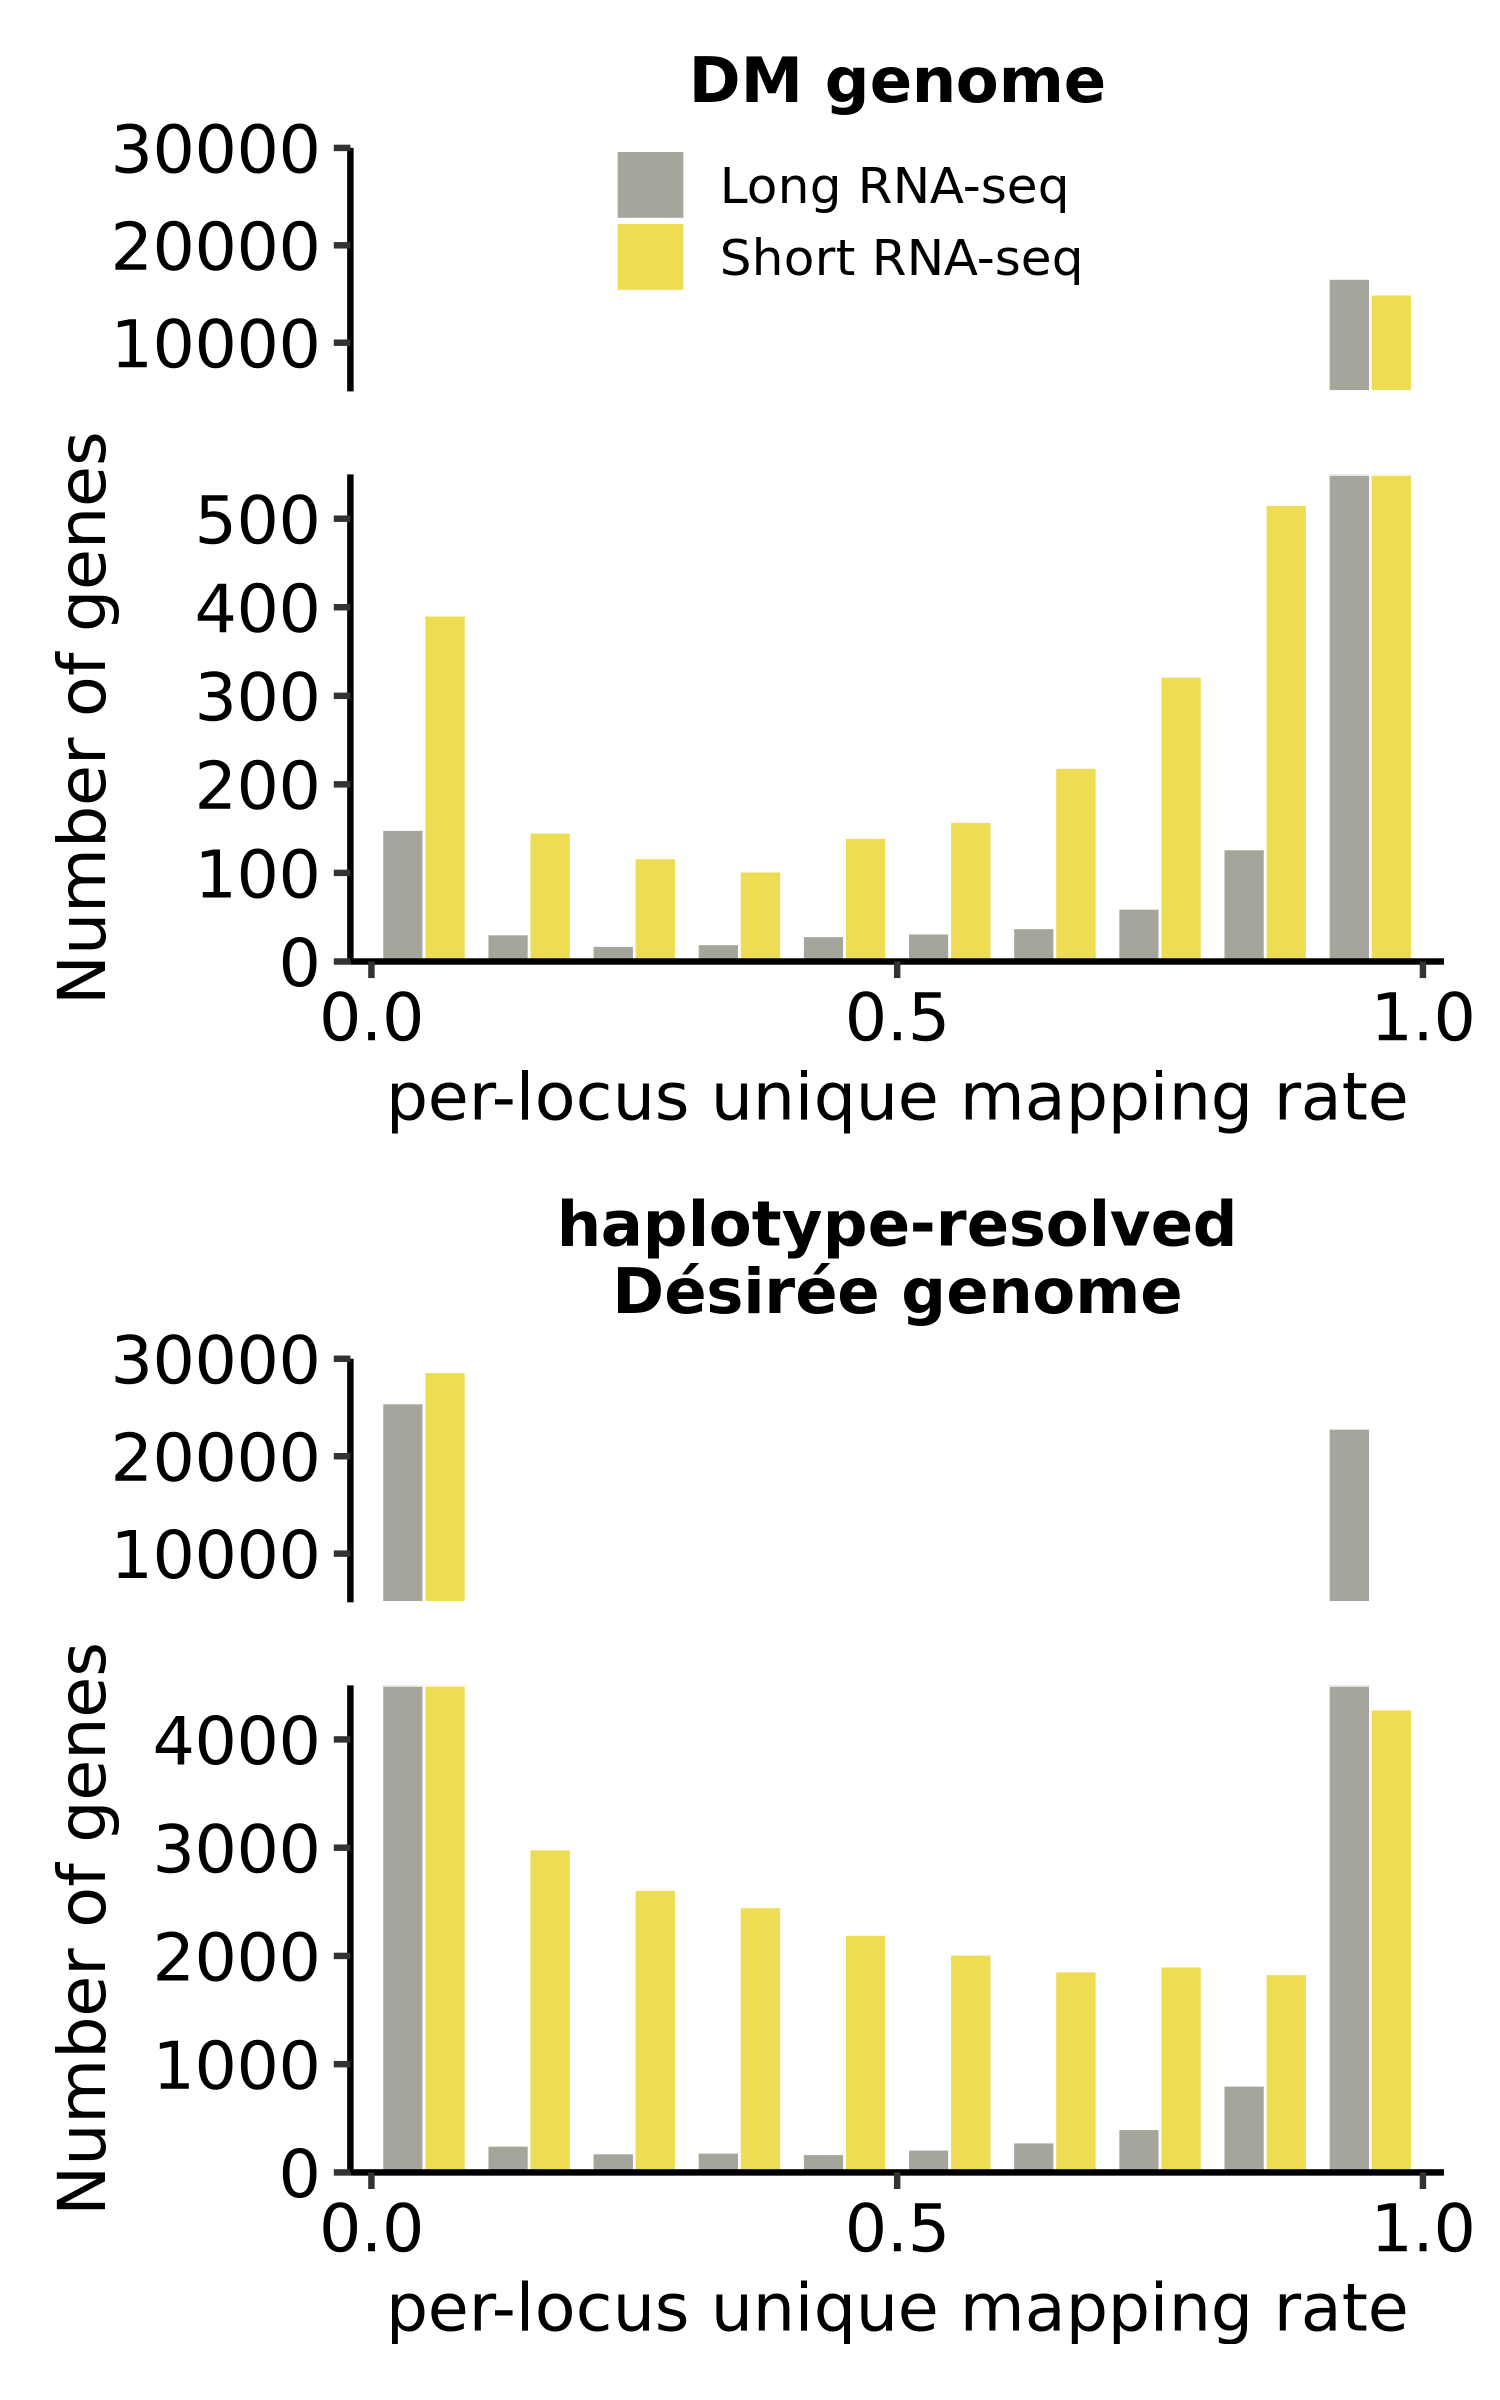

In [31]:
mapping <- read_csv(file.path(DATA_DIR, "unique_mapping_rate_single_isoform_genes.csv"), show_col_types = FALSE)
print(table(mapping$group))

TECH_COLORS <- c("Long RNA-seq" = "#A5A59C", "Short RNA-seq" = "#EEDC54")

broken_histogram <- function(long_group, short_group, title, legend = TRUE) {
  breaks <- seq(0, 1, by = 0.1)
  bin_counts <- function(group, tech) {
    h <- hist(mapping$value[mapping$group == group], breaks = breaks, right = FALSE, plot = FALSE)
    data.frame(mid = h$mids, count = h$counts, tech = tech)
  }
  df <- rbind(bin_counts(long_group, "Long RNA-seq"), bin_counts(short_group, "Short RNA-seq"))
  # upper panel 5,000-30,000 in both graphs; lower panel up to the tallest bar below 5,000
  top_ylim    <- c(5000, 30000)
  lower_max   <- max(df$count[df$count < top_ylim[1]])
  bottom_ylim <- c(0, ceiling(lower_max / 10^floor(log10(lower_max)) * 2) / 2 * 10^floor(log10(lower_max)))
  df$xmin <- ifelse(df$tech == "Long RNA-seq", df$mid - 0.04, df$mid)
  df$xmax <- df$xmin + 0.04

  # bars are drawn as rectangles truncated to each panel's y-range (broken axis)
  panel <- function(ylim) {
    d <- df[df$count > ylim[1], ]
    d$ymin <- ylim[1]
    d$ymax <- pmin(d$count, ylim[2])
    ggplot(d) +
      geom_rect(aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax, fill = tech), color = "white", linewidth = 0.3) +
      scale_fill_manual(values = TECH_COLORS, name = NULL, drop = FALSE) +
      scale_x_continuous(breaks = c(0, 0.5, 1)) +
      coord_cartesian(xlim = c(-0.02, 1.02), ylim = ylim, expand = FALSE) +
      theme_classic(base_size = 16) +
      theme(axis.text = element_text(size = 16, color = "black"))
  }

  top <- panel(top_ylim) +
    scale_y_continuous(breaks = seq(10000, top_ylim[2], by = 10000)) +
    labs(title = title, x = NULL, y = NULL) +
    theme(axis.line.x = element_blank(), axis.ticks.x = element_blank(), axis.text.x = element_blank(),
          plot.title = element_text(size = 15, face = "bold", hjust = 0.5),
          legend.position = if (legend) "inside" else "none", legend.position.inside = c(0.45, 0.7),
          legend.background = element_blank(), legend.text = element_text(size = 12))
  bottom <- panel(bottom_ylim) +
    labs(x = "per-locus unique mapping rate", y = "Number of genes") +
    theme(legend.position = "none")

  top / bottom + plot_layout(heights = c(1, 2))
}

p_b_dm  <- broken_histogram("long RNA-seq haploid", "short RNA-seq haploid", "DM genome")
p_b_hap <- broken_histogram("long RNA-seq phased", "short RNA-seq phased", "haplotype-resolved\nDésirée genome", legend = FALSE)

options(repr.plot.width = 5, repr.plot.height = 8, repr.plot.res = 300)
p_b <- wrap_plots(p_b_dm, p_b_hap, ncol = 1)
p_b
ggsave(file.path(OUT_DIR, "Fig1B_unique_mapping_rate_histogram.svg"), plot = p_b, width = 5, height = 8)

## Panel C — log2FC correlation between short- and long-read RNA-seq

All scatterplots (C, E, F) use **single-isoform genes** only (one transcript in the long-read
tx2gene), so that gene-level log2FC is not affected by isoform assignment.

**DM genome:** single-isoform genes passing the expression filter in both data sets.

**Haplotype-resolved genome:** single-isoform alleles passing the expression filter in both data sets.

DM genes tested in both: 15010 | single-isoform: 9170 
# A tibble: 1 × 3
      r     n label                       
  <dbl> <int> <chr>                       
1 0.772  9170 "Pearson r = 0.77\nn = 9170"


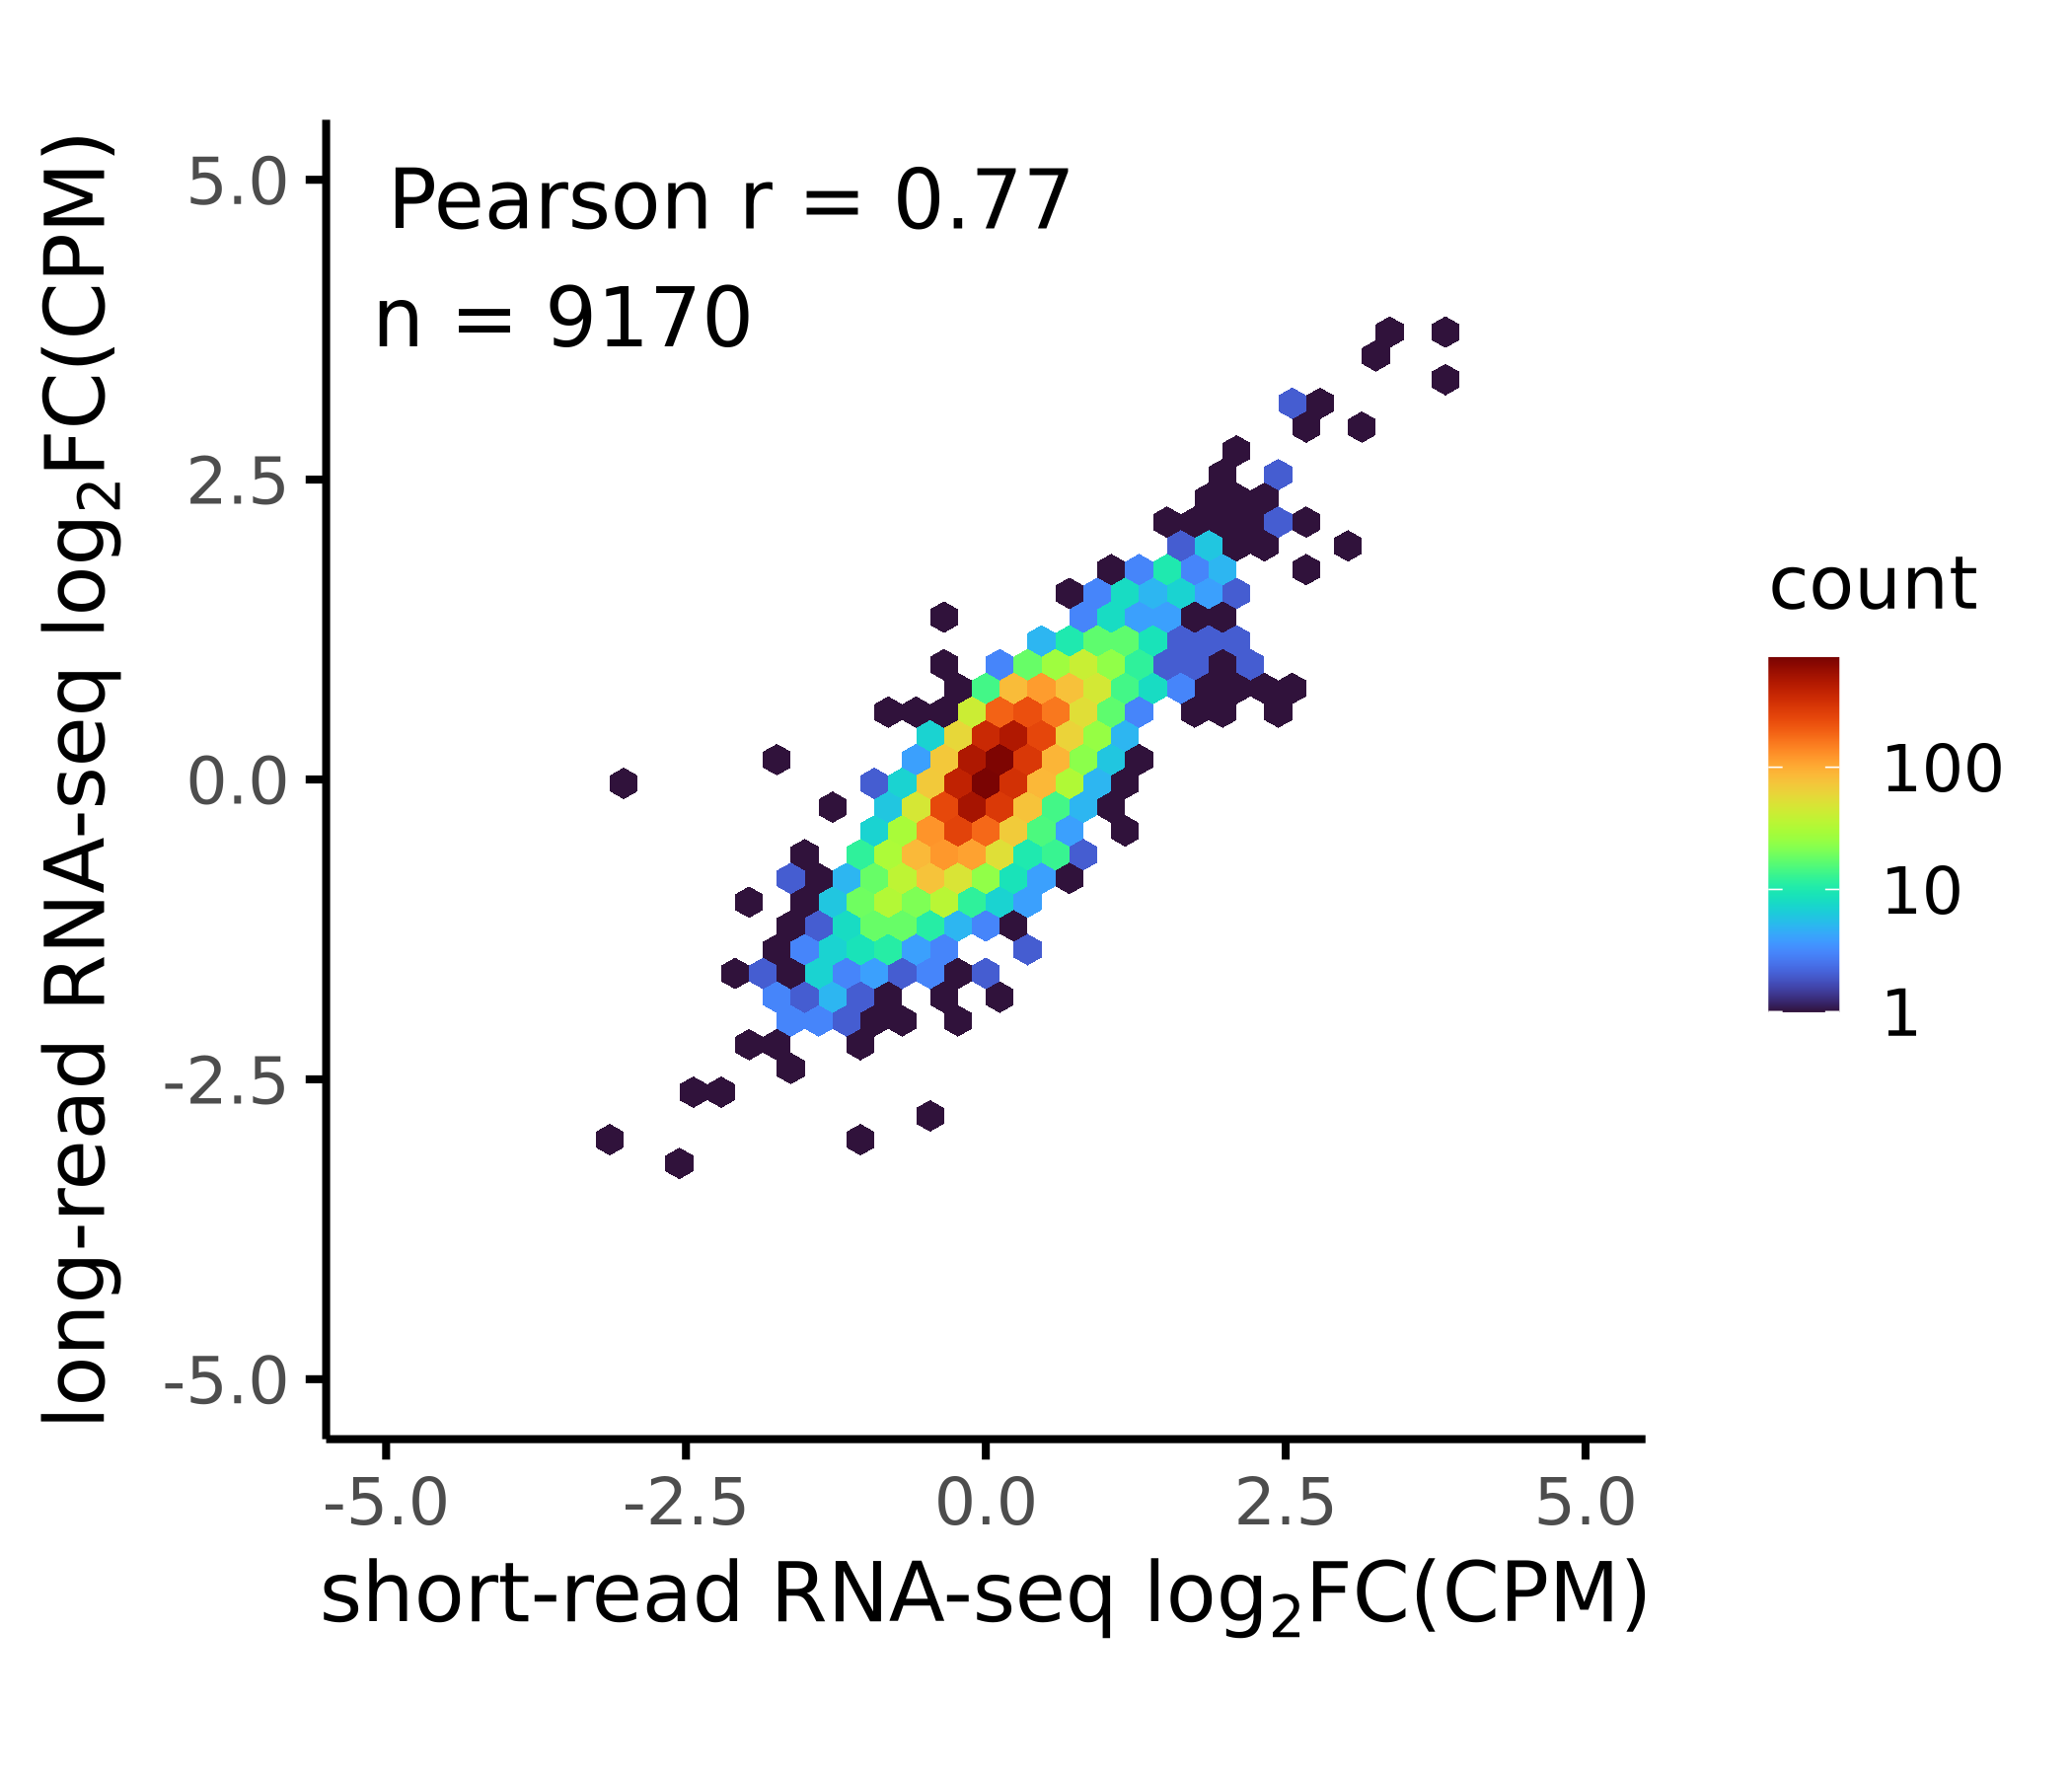

In [32]:
single_isoform_dm  <- read_csv(file.path(DATA_DIR, "single_isoform_genes_DM.csv"), show_col_types = FALSE)$gene_id
single_isoform_hap <- read_csv(file.path(DATA_DIR, "single_isoform_genes_hap.csv"), show_col_types = FALSE)$gene_id

dm_genes <- intersect(rownames(dm_long), rownames(dm_short))
cat("DM genes tested in both:", length(dm_genes))
dm_genes <- intersect(dm_genes, single_isoform_dm)
cat(" | single-isoform:", length(dm_genes), "\n")
dm_pairs <- paired_logfc(dm_long, dm_short, dm_genes)

options(repr.plot.width = 7, repr.plot.height = 6, repr.plot.res = 300)
p_c_dm <- logfc_hex_plot(dm_pairs)
p_c_dm
ggsave(file.path(OUT_DIR, "Fig1C_logFC_correlation_DM.svg"), plot = p_c_dm, width = 7, height = 6, dpi = 300)

alleles tested in both: 27433

 | single-isoform: 14625 
# A tibble: 1 × 3
      r     n label                        
  <dbl> <int> <chr>                        
1 0.717 14625 "Pearson r = 0.72\nn = 14625"


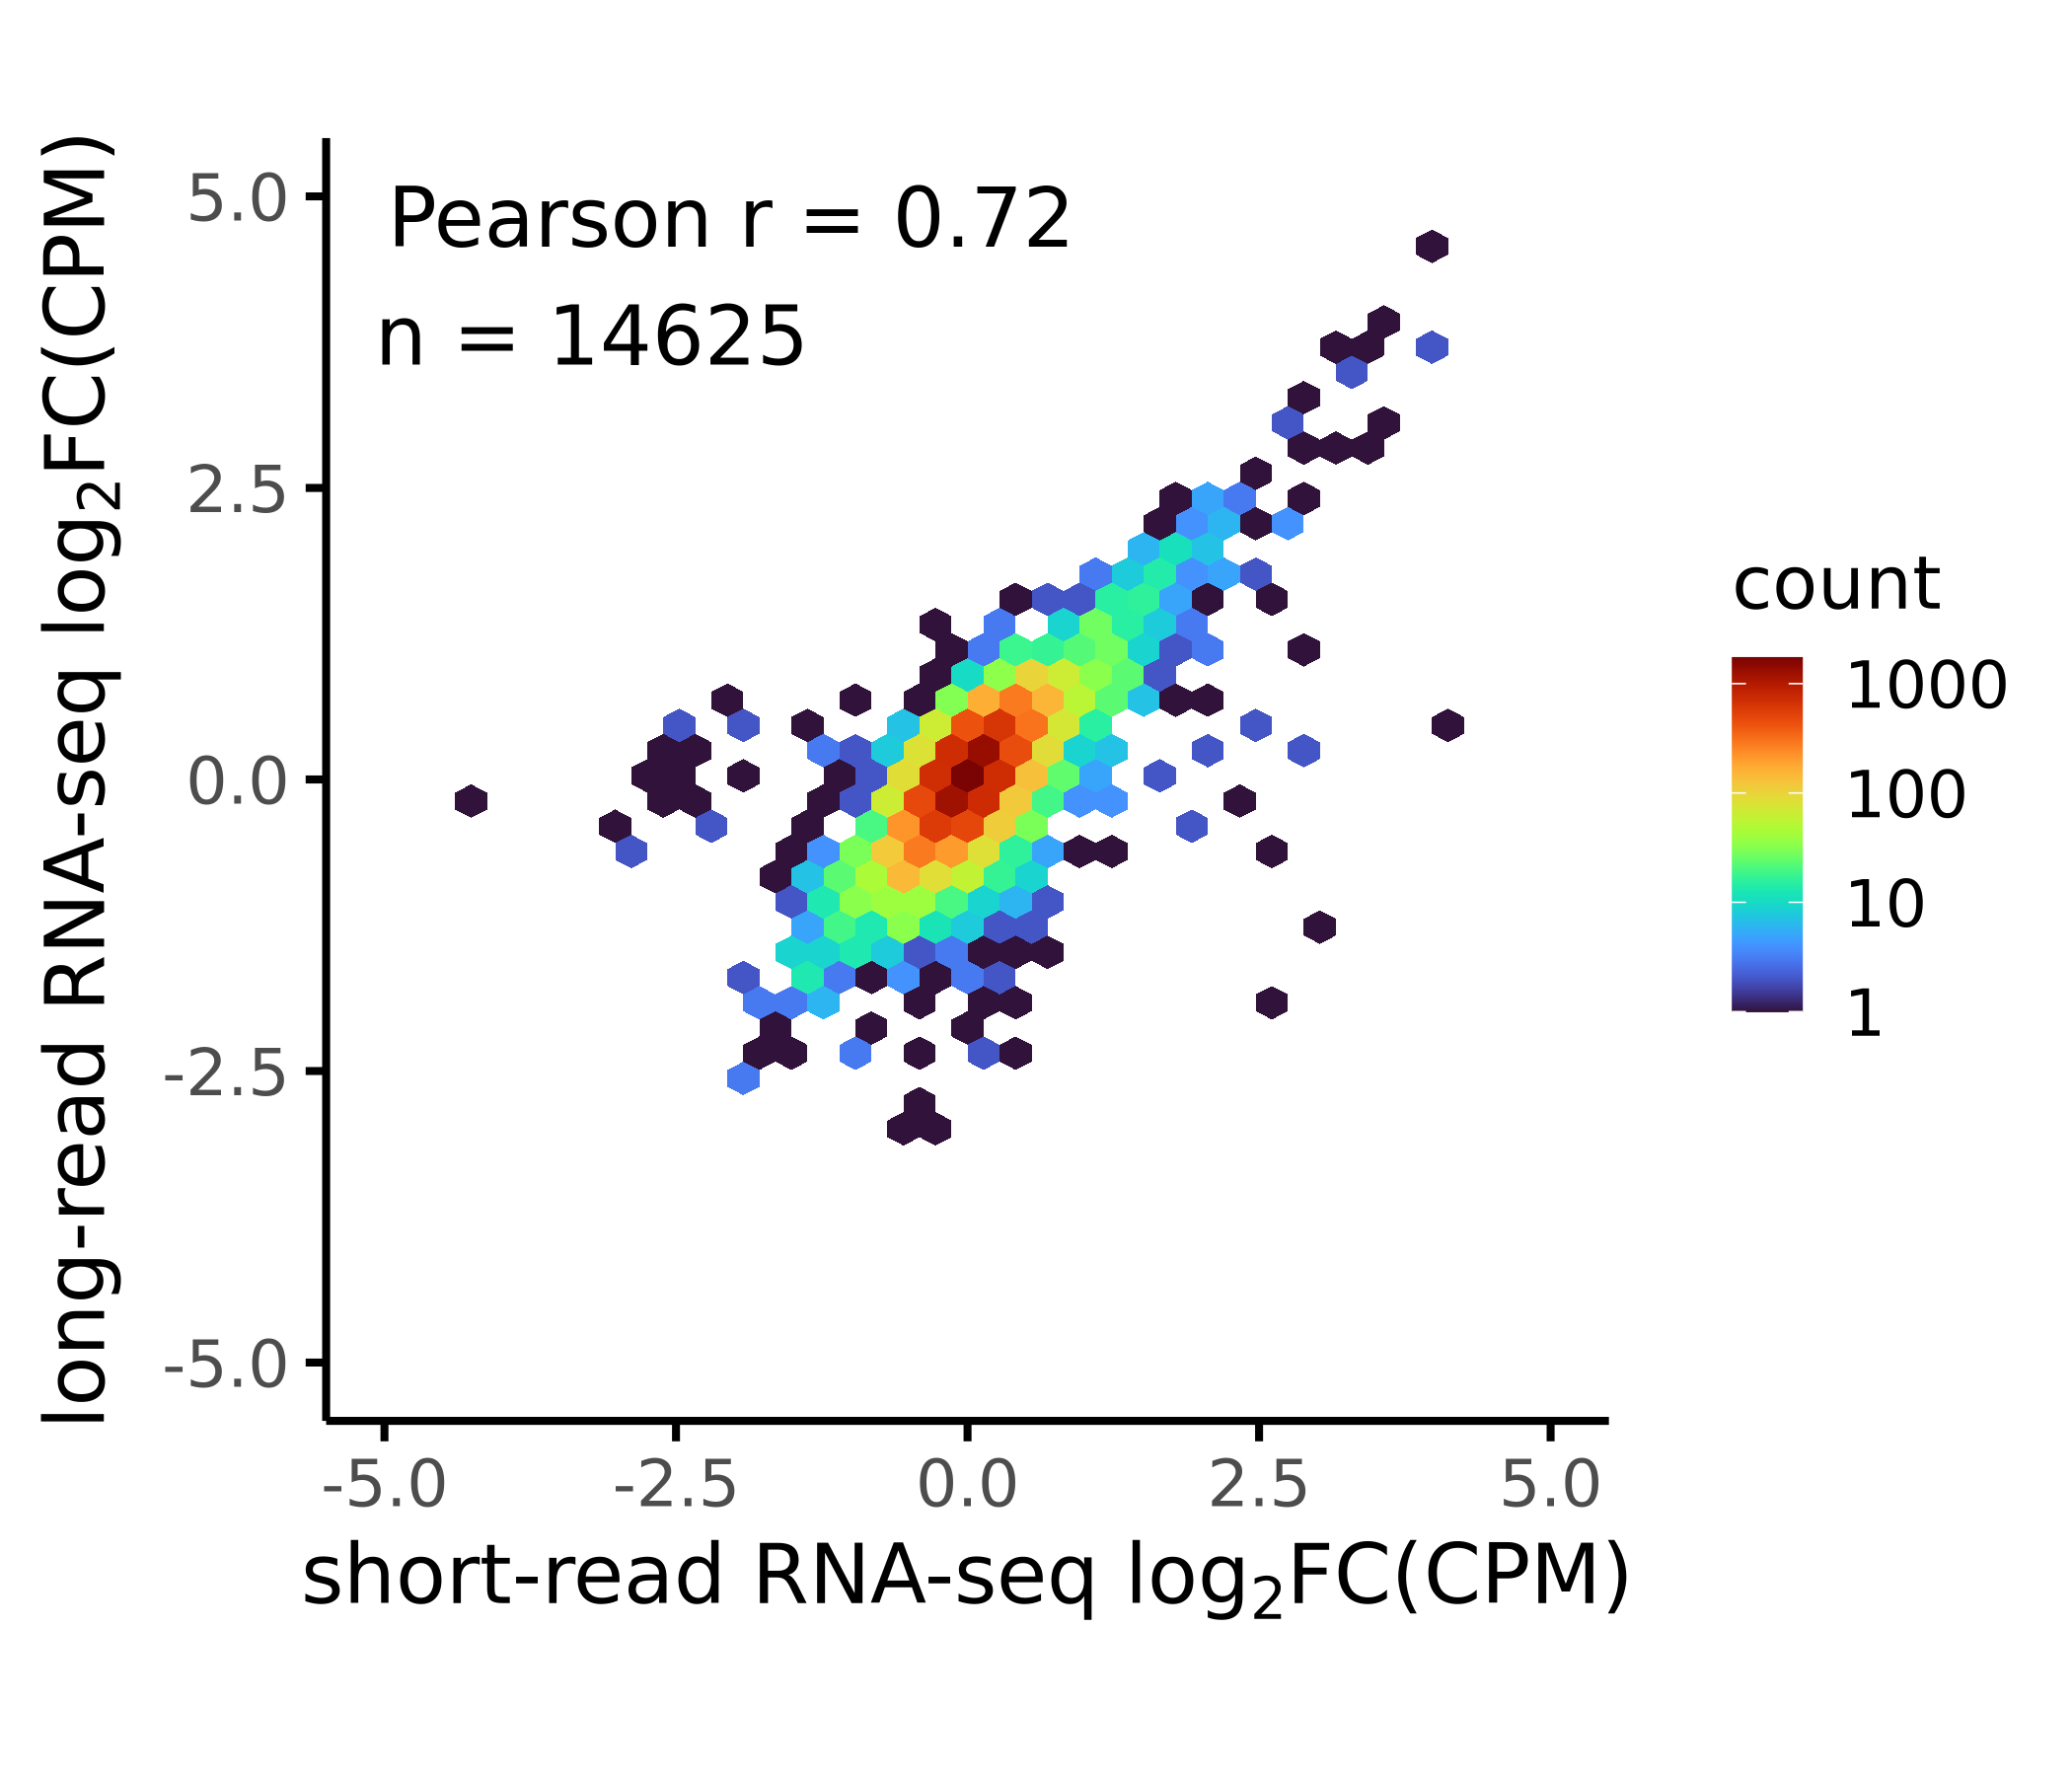

In [33]:
hap_genes <- intersect(rownames(hap_long), rownames(hap_short))
cat("alleles tested in both:", length(hap_genes))
hap_genes <- intersect(hap_genes, single_isoform_hap)
cat(" | single-isoform:", length(hap_genes), "\n")
hap_pairs <- paired_logfc(hap_long, hap_short, hap_genes)

options(repr.plot.width = 7, repr.plot.height = 6, repr.plot.res = 300)
p_c_hap <- logfc_hex_plot(hap_pairs)
p_c_hap
ggsave(file.path(OUT_DIR, "Fig1C_logFC_correlation_haplotype_resolved.svg"), plot = p_c_hap, width = 7, height = 6, dpi = 300)

## Panel D — Overlap of DEGs between long- and short-read RNA-seq

DEG: |log2FC| > 1 and adj. p < 0.01. As in the source notebooks, short-read DEGs are taken from genes
also tested in the *uncorrected* long-read fit, long-read DEGs from the batch-corrected fit restricted
to genes also tested in short-read. All genes are included here (also novel genes, no mapping-rate filter).

The arrows give the number of up-/down-regulated genes per region (direction from long-read for
long-only and shared, from short-read for short-only).

In [34]:
deg_table <- function(long, uncorr, short) {
  res_long  <- long[intersect(rownames(long), rownames(short)), ]
  res_short <- short[intersect(rownames(uncorr), rownames(short)), ]
  direction <- function(res) {
    sig <- res$adj.P.Val < ADJP_CUT & abs(res$logFC) > LOGFC_CUT
    setNames(ifelse(res$logFC > 0, "up", "down")[sig], rownames(res)[sig])
  }
  long_dir  <- direction(res_long)
  short_dir <- direction(res_short)
  genes <- union(names(long_dir), names(short_dir))
  data.frame(gene_id = genes,
             long  = unname(long_dir[genes]),
             short = unname(short_dir[genes]),
             functional_annotation = coalesce(long[genes, "functional_annotation"], short[genes, "functional_annotation"])) %>%
    mutate(region = case_when(!is.na(long) & !is.na(short) ~ "both",
                              !is.na(long) ~ "long-read only",
                              TRUE ~ "short-read only"),
           direction = coalesce(long, short))
}

draw_deg_venn <- function(degs, file) {
  counts <- degs %>% count(region, direction) %>% tidyr::pivot_wider(names_from = direction, values_from = n, values_fill = 0)
  print(counts)
  cat("shared DEGs with opposite direction:", sum(degs$region == "both" & degs$long != degs$short), "\n")

  draw <- function() {
    grid.newpage()
    venn <- draw.pairwise.venn(
      area1 = sum(!is.na(degs$long)), area2 = sum(!is.na(degs$short)),
      cross.area = sum(degs$region == "both"),
      category = c("long-read", "short-read"),
      fill = c("grey", "darkorange2"), alpha = 0.5,
      cex = 1.5, fontface = "bold", fontfamily = "sans",
      cat.cex = 1.3, cat.fontface = "bold", cat.fontfamily = "sans",
      cat.pos = c(-20, 20), cat.dist = c(0.05, 0.05),
      ext.text = TRUE, ext.line.lwd = 1.5, ext.dist = -0.15, ext.length = 0.85,
      lwd = 2, lty = "solid", col = c("black", "black"),
      ind = FALSE
    )
    grid.draw(venn)
    # up/down counts below each region's number
    for (region in c("long-read only", "both", "short-read only")) {
      n_region <- sum(degs$region == region)
      lab <- Filter(function(g) inherits(g, "text") && identical(as.character(g$label), as.character(n_region)), venn)
      if (length(lab) == 0) next
      sub <- counts[counts$region == region, ]
      grid.text(paste0("↑", sub$up, " ↓", sub$down),
                x = lab[[1]]$x, y = lab[[1]]$y - unit(0.07, "npc"),
                gp = gpar(fontsize = 11, fontfamily = "sans"))
    }
  }
  svglite(file, width = 3.5, height = 3.5)
  draw()
  invisible(dev.off())
  options(repr.plot.width = 3.5, repr.plot.height = 3.5, repr.plot.res = 300)
  draw()
}

# A tibble: 3 × 3
  region           down    up
  <chr>           <int> <int>
1 both              112   194
2 long-read only    209    79
3 short-read only    42   108
shared DEGs with opposite direction: 0 


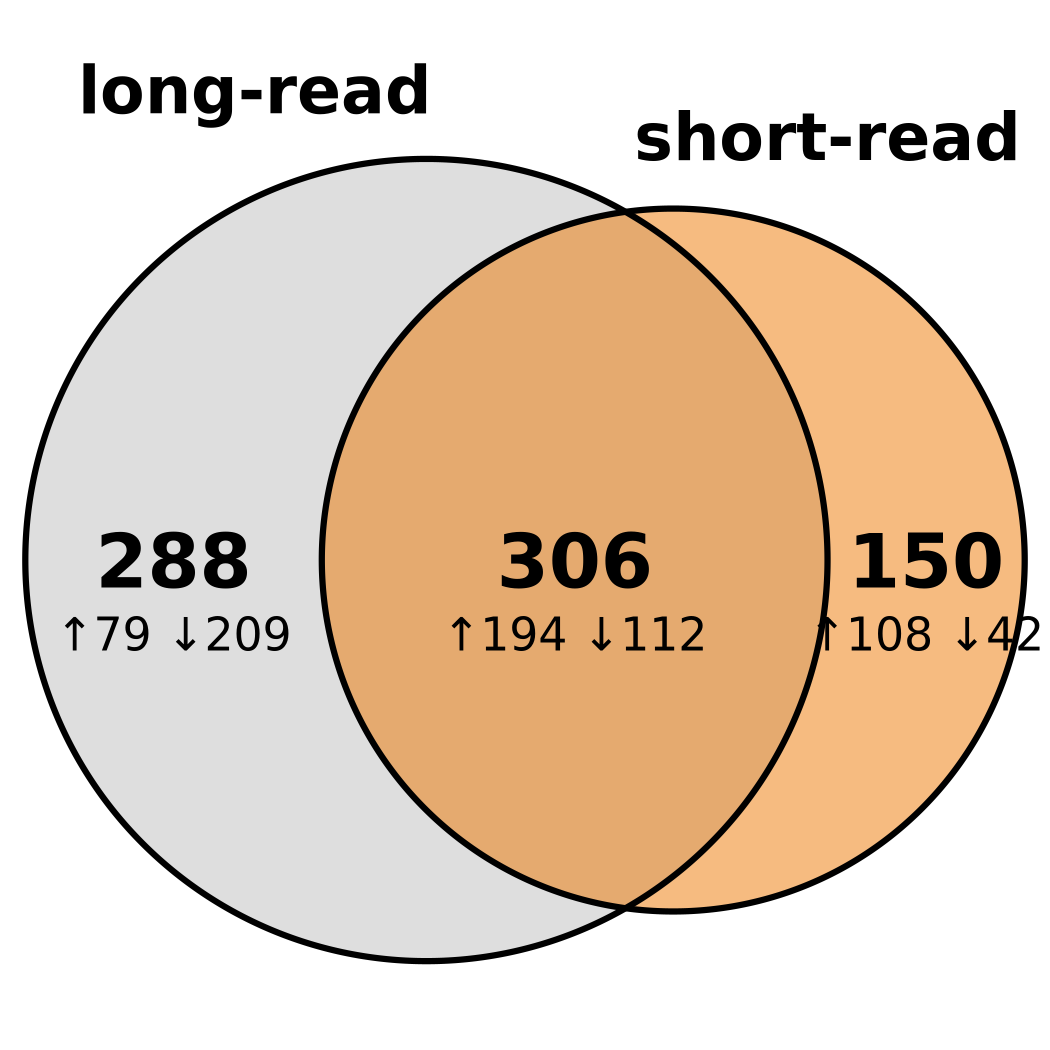

In [35]:
dm_degs <- deg_table(dm_long, dm_uncorr, dm_short)
draw_deg_venn(dm_degs, file.path(OUT_DIR, "Fig1D_DEG_overlap_venn_DM.svg"))

# A tibble: 3 × 3
  region           down    up
  <chr>           <int> <int>
1 both              157   313
2 long-read only    306   120
3 short-read only    80   142
shared DEGs with opposite direction: 0 


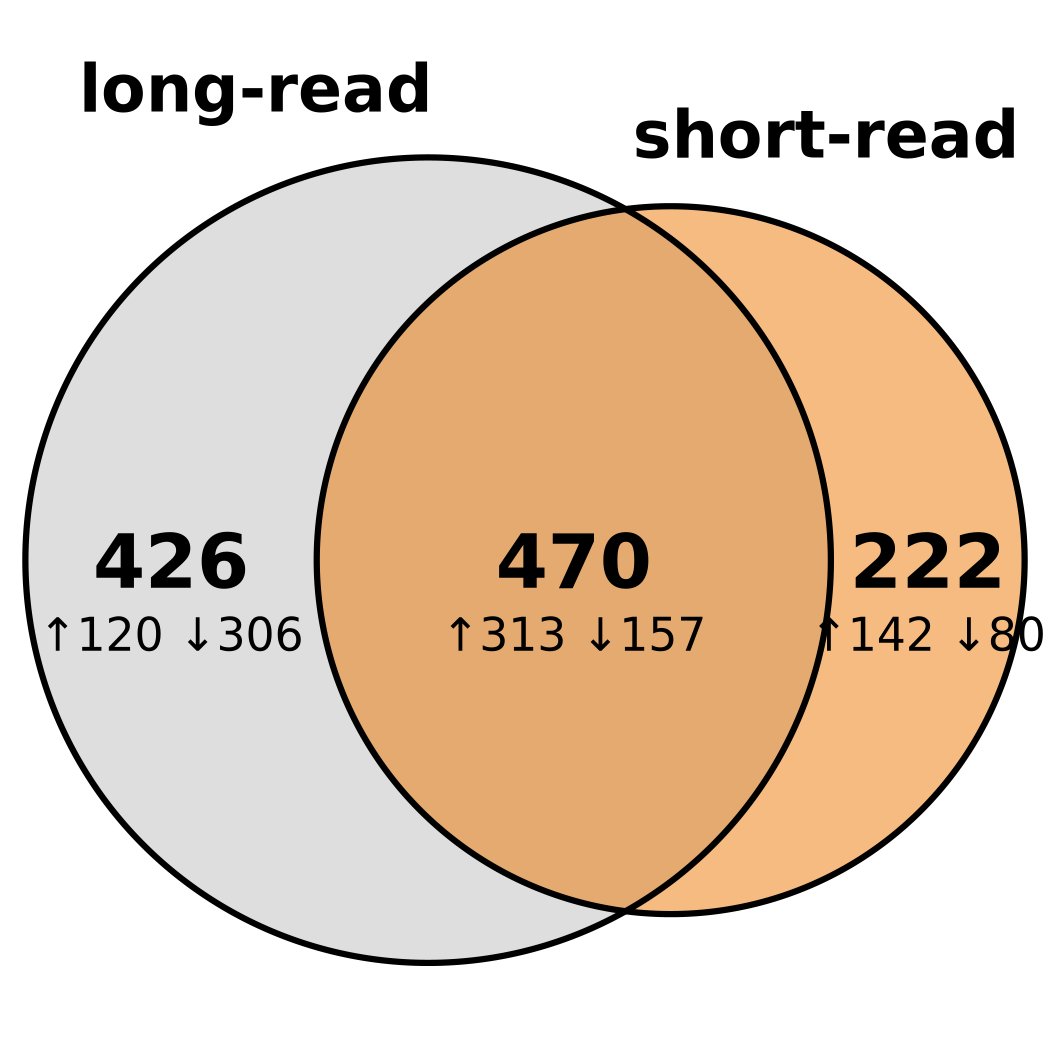

In [36]:
hap_degs <- deg_table(hap_long, hap_uncorr, hap_short)
draw_deg_venn(hap_degs, file.path(OUT_DIR, "Fig1D_DEG_overlap_venn_haplotype_resolved.svg"))

In [37]:
# DEG lists behind the Venn diagrams, with functional annotation
write_csv(dm_degs,  file.path(OUT_DIR, "Fig1D_DEG_overlap_DM.csv"))
write_csv(hap_degs, file.path(OUT_DIR, "Fig1D_DEG_overlap_haplotype_resolved.csv"))

## Panel E — log2FC correlation by transcript length (DM genome)

Same single-isoform genes as panel C (top), binned by the average transcript length (`avgTxlengths_desiree_unitato.tsv`).

# A tibble: 4 × 4
  length_bin       r     n label                       
  <fct>        <dbl> <int> <chr>                       
1 < 0.75 kb    0.658   563 "Pearson r = 0.66\nn = 563" 
2 0.75-1.25 kb 0.790  1870 "Pearson r = 0.79\nn = 1870"
3 1.25-3.5 kb  0.779  6130 "Pearson r = 0.78\nn = 6130"
4 > 3.5 kb     0.790   607 "Pearson r = 0.79\nn = 607" 


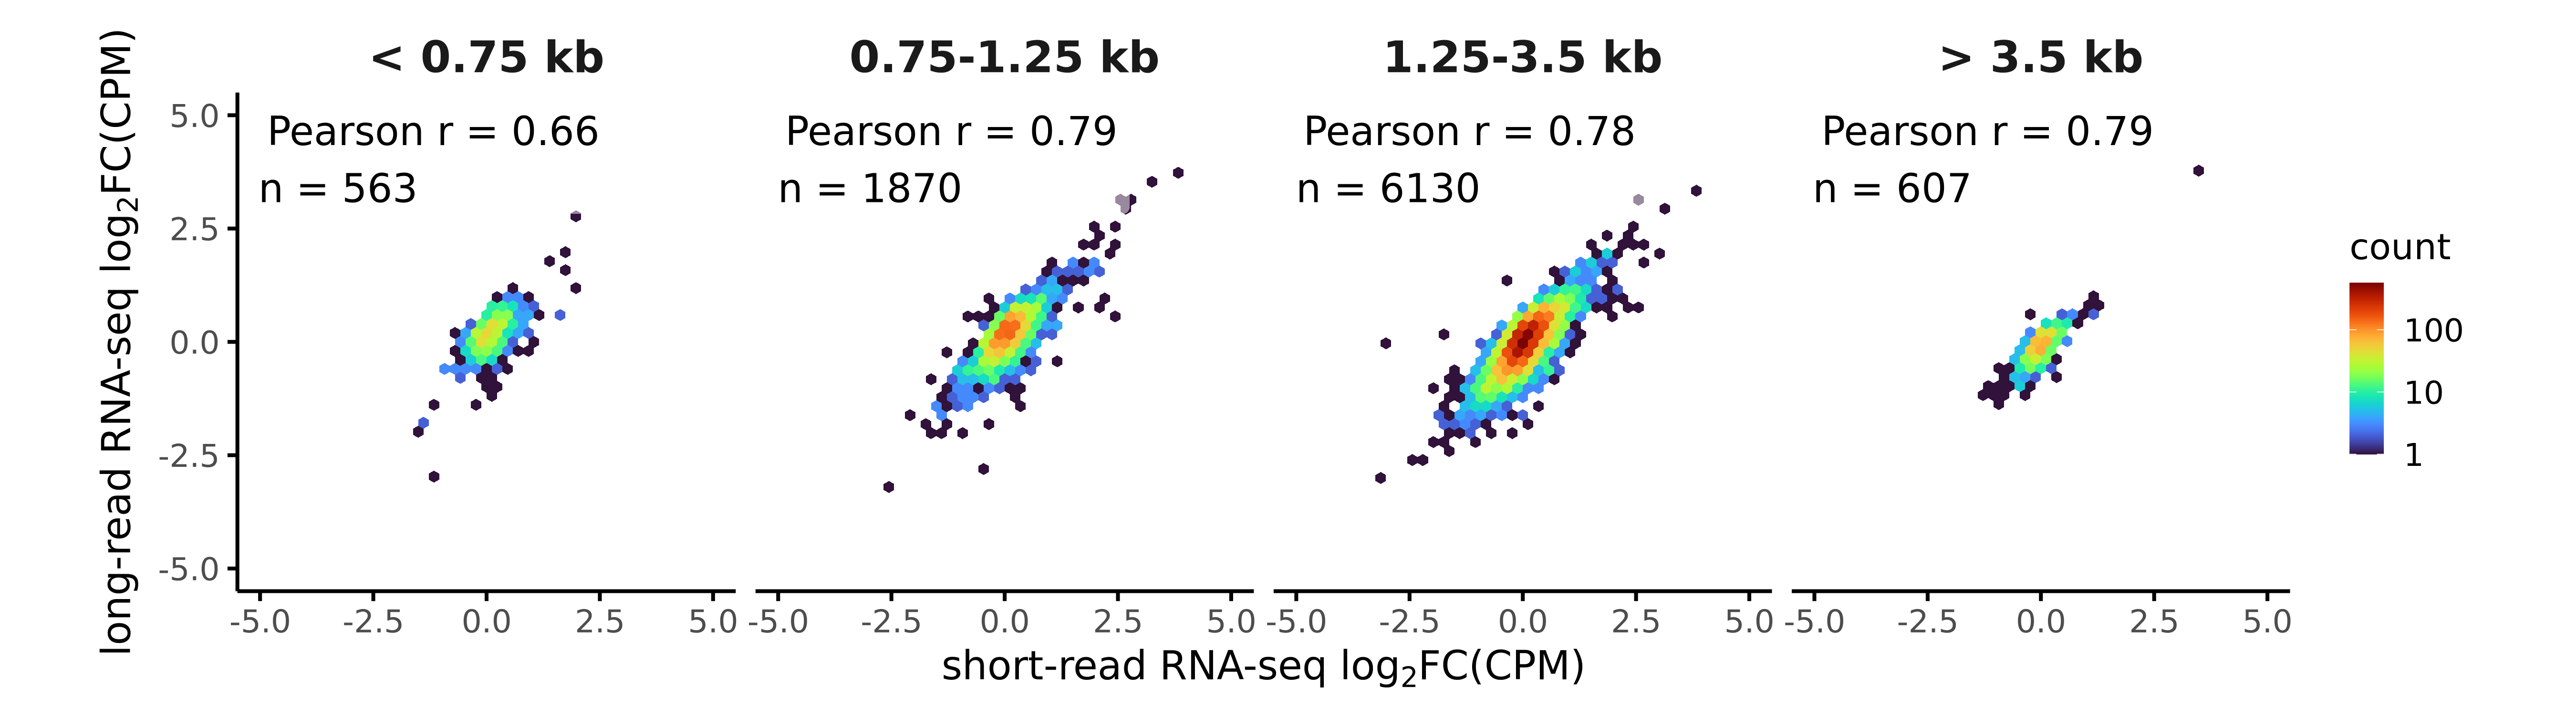

In [38]:
gene_length <- read.table(file.path(DATA_DIR, "avgTxlengths_desiree_unitato.tsv"), header = TRUE)
gene_length$gene_id <- rownames(gene_length)
colnames(gene_length) <- c("AvgTranscriptLength", "gene_id")

dm_pairs_length <- merge(dm_pairs, gene_length, by = "gene_id") %>%
  mutate(length_bin = cut(
    AvgTranscriptLength,
    breaks = c(0, 750, 1250, 3500, Inf),
    include.lowest = TRUE,
    labels = c("< 0.75 kb", "0.75-1.25 kb", "1.25-3.5 kb", "> 3.5 kb")
  ))

options(repr.plot.width = 18, repr.plot.height = 5, repr.plot.res = 300)
p_e <- logfc_hex_plot(dm_pairs_length, facet = "length_bin")
p_e
ggsave(file.path(OUT_DIR, "Fig1E_logFC_correlation_by_transcript_length.svg"), plot = p_e, width = 18, height = 5, dpi = 300)

## Panel F — log2FC correlation by unique mapping rate (haplotype-resolved genome)

Same alleles as panel C (bottom), binned by the short-read unique mapping rate. As in panel B, the
rate is computed for single-isoform genes, with reads summed over all 8 samples (salmon).

alleles in panel C: 14625 | with a single-isoform mapping rate: 14625 
# A tibble: 4 × 4
  mapping_bin     r     n label                        
  <fct>       <dbl> <int> <chr>                        
1 0–0.05      0.675  7209 "Pearson r = 0.675\nn = 7209"
2 0.05–0.1    0.729   546 "Pearson r = 0.729\nn = 546" 
3 0.1–0.5     0.749  3951 "Pearson r = 0.749\nn = 3951"
4 0.5–1.0     0.781  2919 "Pearson r = 0.781\nn = 2919"


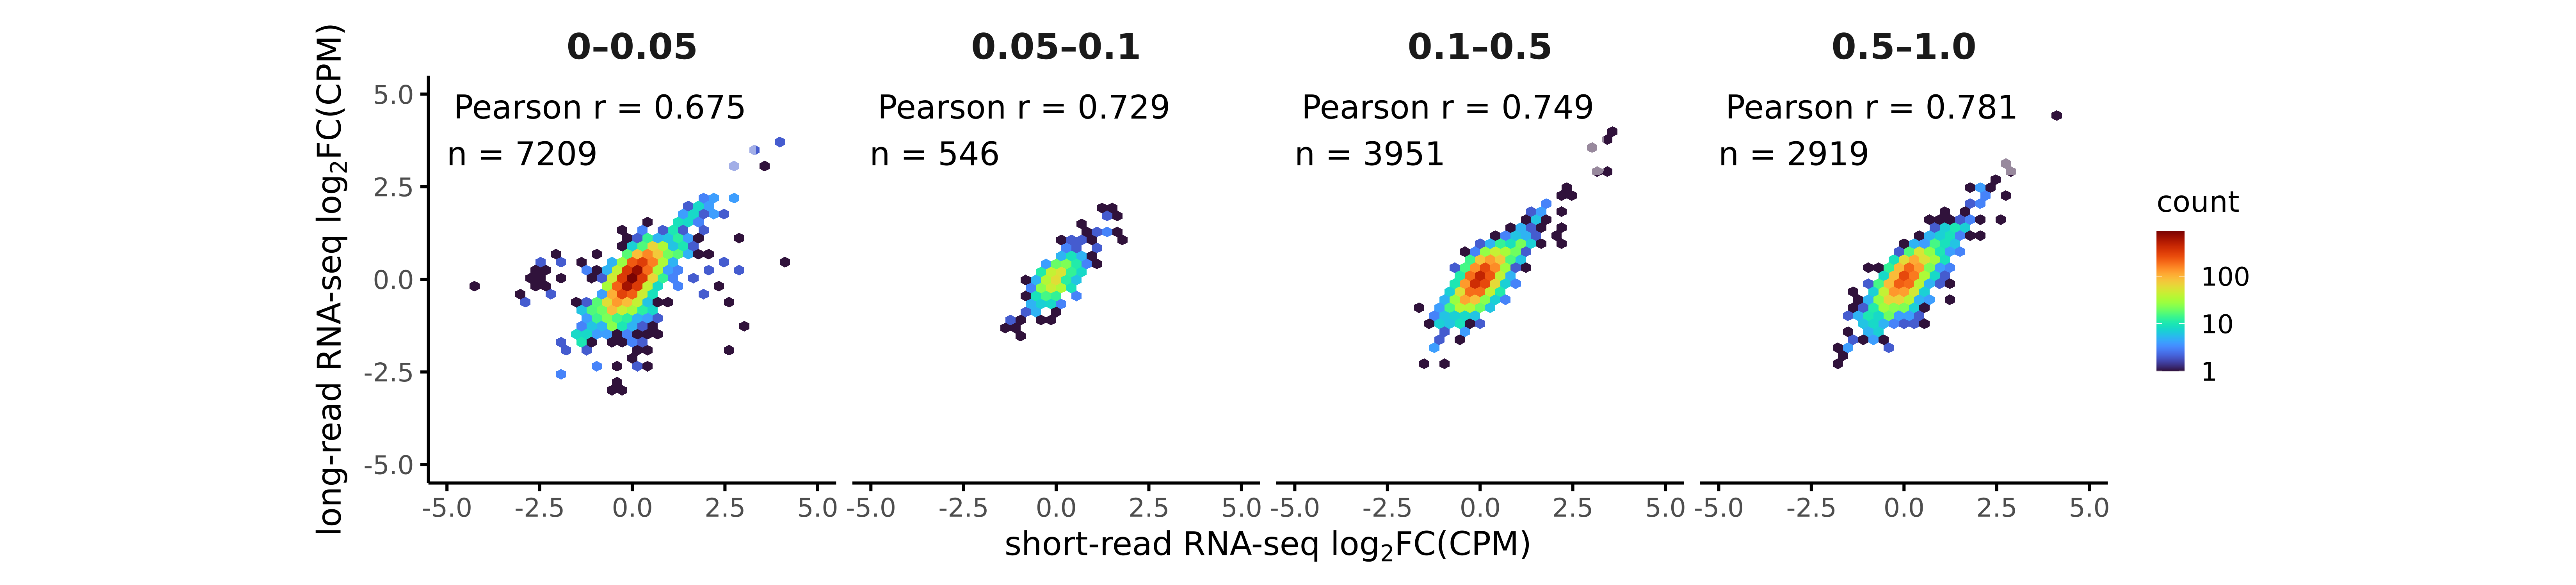

In [39]:
short_ratio <- read_csv(file.path(DATA_DIR, "hap_short_unique_mapping_rate_single_isoform.csv"), show_col_types = FALSE)

hap_pairs_mapping <- hap_pairs %>%
  mutate(unique_mapping_ratio = short_ratio$UniqueMappingRatio[match(gene_id, short_ratio$gene_id)],
         mapping_bin = cut(
           unique_mapping_ratio,
           breaks = c(0, 0.05, 0.1, 0.5, 1),
           include.lowest = TRUE,
           labels = c("0–0.05", "0.05–0.1", "0.1–0.5", "0.5–1.0")
         )) %>%
  filter(!is.na(mapping_bin))
cat("alleles in panel C:", nrow(hap_pairs), "| with a single-isoform mapping rate:", nrow(hap_pairs_mapping), "\n")

options(repr.plot.width = 22, repr.plot.height = 5, repr.plot.res = 300)
p_f <- logfc_hex_plot(hap_pairs_mapping, facet = "mapping_bin", digits = 3)
p_f
ggsave(file.path(OUT_DIR, "Fig1F_logFC_correlation_by_unique_mapping_rate.svg"), plot = p_f, width = 22, height = 5, dpi = 300)